# Fase 3 — EDA: Análisis exploratorio de datos
**Objetivo:** entender cómo consume energía la planta: cuándo, cuánto y con qué eficiencia. A partir de eso formulamos **hipótesis** que se pondrán a prueba con los modelos de la Fase 4.

**Insumo:** las tablas limpias generadas por `01_ETL.ipynb` (ejecútenlo primero).

**Estructura:**
1. Estadística descriptiva.
2. KPIs industriales del año.
3. Ocho visualizaciones, cada una con su interpretación.
4. Hipótesis para el modelado.

## 1. Configuración
Además de pandas y numpy usamos:
- `matplotlib.pyplot`: la librería base de gráficos en Python.
- `seaborn`: se construye sobre matplotlib y simplifica gráficos estadísticos (mapas de calor, boxplots).

Definimos un **estilo común** (colores fijos por categoría, ejes y cuadrícula discretos) para que todas las figuras sean consistentes. Cada figura se guarda en `reports/figures/` para usarla en el reporte.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_PROC = BASE / "data" / "processed"
RUTA_FIG = BASE / "reports" / "figures"
RUTA_TABLAS = BASE / "reports" / "tablas"
RUTA_FIG.mkdir(parents=True, exist_ok=True)

# Estilo de gráficos
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8986", "axes.titleweight": "bold", "axes.titlesize": 11})
AZUL, NARANJA, AGUAMARINA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
COLOR_CARGA = {"Light_Load": AZUL, "Medium_Load": NARANJA, "Maximum_Load": AGUAMARINA}
ETQ_CARGA = {"Light_Load": "Ligera", "Medium_Load": "Media", "Maximum_Load": "Máxima"}
ORDEN_CARGA = ["Light_Load", "Medium_Load", "Maximum_Load"]
DIAS_ES = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

def guardar(fig, nombre):
    fig.savefig(RUTA_FIG / f"{nombre}.png", bbox_inches="tight")

df = pd.read_csv(RUTA_PROC / "consumo_15min_limpio.csv", parse_dates=["ts_inicio", "ts_fin", "fecha"])
df["tipo_carga"] = pd.Categorical(df["tipo_carga"], categories=ORDEN_CARGA, ordered=True)
horaria = pd.read_csv(RUTA_PROC / "consumo_horario.csv", parse_dates=["ts_inicio"])
diaria = pd.read_csv(RUTA_PROC / "consumo_diario.csv", parse_dates=["fecha"])
print(df.shape, horaria.shape, diaria.shape)

(35040, 24) (8760, 8) (365, 14)


**Error común:** al leer un CSV las fechas vuelven a ser texto y las categorías pierden su orden. Por eso usamos `parse_dates=[...]` y volvemos a definir `pd.Categorical(..., ordered=True)`.

## 2. Estadística descriptiva
`.describe()` resume cada variable numérica. Agregamos el **coeficiente de variación** (CV = desviación estándar / media), que permite comparar la variabilidad de variables con unidades distintas.

In [2]:
vars_num = ["energia_kwh", "demanda_kw", "reactiva_ind_kvarh", "reactiva_cap_kvarh", "fp_ind_pct", "fp_cap_pct", "co2_kg_est"]
desc = df[vars_num].describe().T
desc["CV_%"] = (desc["std"] / desc["mean"] * 100)
desc["asimetria"] = df[vars_num].skew()
desc = desc.round(2)
desc.to_csv(RUTA_TABLAS / "estadistica_descriptiva.csv")
desc

,count,mean,std,min,25%,50%,75%,max,CV_%,asimetria
energia_kwh,35040.0,27.39,33.44,2.45,3.20,4.57,51.24,157.18,122.12,1.20
demanda_kw,35040.0,109.55,133.78,9.80,12.80,18.28,204.95,628.72,122.12,1.20
reactiva_ind_kvarh,35040.0,13.04,16.31,0.00,2.30,5.00,22.64,96.91,125.09,1.44
reactiva_cap_kvarh,35040.0,3.87,7.42,0.00,0.00,0.00,2.09,27.76,191.80,1.73
fp_ind_pct,35040.0,80.58,18.92,36.94,63.32,87.96,99.02,100.00,23.48,-0.60
fp_cap_pct,35040.0,84.37,30.45,12.50,99.70,100.00,100.00,100.00,36.09,-1.51
co2_kg_est,35040.0,12.63,15.42,1.13,1.48,2.11,23.62,72.47,122.12,1.20


**Interpretación:**
- La **mediana** del consumo (4,6 kWh por intervalo) es muy inferior a la **media** (27,4 kWh): la mayor parte del tiempo la planta consume poco y en algunos periodos consume mucho. Por eso la distribución es asimétrica a la derecha (asimetría 1,2).
- El **CV de la energía (~122 %)** indica una variabilidad muy alta, típica de una planta que alterna periodos de producción y de parada.
- El FP inductivo tiene una mediana de 88 %, **por debajo del 90 %** que se considera una referencia técnica de buen desempeño: hay un problema de eficiencia eléctrica que conviene investigar.

### 2.1 Descriptiva por tipo de carga
Con `groupby` comparamos las variables según el tipo de carga (la futura variable objetivo de la clasificación).

In [3]:
por_carga = df.groupby("tipo_carga", observed=True).agg(
    intervalos=("energia_kwh", "size"),
    energia_media_kwh=("energia_kwh", "mean"),
    energia_mediana_kwh=("energia_kwh", "median"),
    energia_total_kwh=("energia_kwh", "sum"),
    fp_ind_medio=("fp_ind_pct", "mean"),
    pct_fp_bajo=("fp_bajo", "mean"),
    hora_media=("hora", "mean"),
)
por_carga["pct_intervalos"] = por_carga["intervalos"] / por_carga["intervalos"].sum() * 100
por_carga["pct_energia"] = por_carga["energia_total_kwh"] / por_carga["energia_total_kwh"].sum() * 100
por_carga["pct_fp_bajo"] *= 100
por_carga = por_carga.round(1)
por_carga.to_csv(RUTA_TABLAS / "descriptiva_por_tipo_carga.csv")
por_carga

,intervalos,energia_media_kwh,energia_mediana_kwh,energia_total_kwh,fp_ind_medio,pct_fp_bajo,hora_media,pct_intervalos,pct_energia
tipo_carga,,,,,,,,,
Light_Load,18072,8.6,3.3,155896.4,69.7,79.3,7.7,51.6,16.2
Medium_Load,9696,38.4,34.4,372766.5,93.1,21.5,16.5,27.7,38.8
Maximum_Load,7272,59.3,56.6,430977.4,91.0,38.4,14.1,20.8,44.9


**Interpretación:** la carga ligera ocupa el **51,6 % del tiempo** pero solo el **16,2 % de la energía**. Sin embargo, es donde el FP es peor: el **79 %** de sus intervalos tienen FP < 90 %. Las cargas media y máxima concentran el 84 % del consumo.

## 3. KPIs industriales del año
Calculamos los indicadores que un jefe de planta revisaría en un tablero de gestión energética.

In [4]:
energia_total = df["energia_kwh"].sum()
reactiva_total = df["reactiva_ind_kvarh"].sum()
kpis = {
    "Energía activa anual (MWh)": energia_total / 1000,
    "Demanda máxima (kW)": df["demanda_kw"].max(),
    "Demanda media (kW)": df["demanda_kw"].mean(),
    "Factor de carga anual": df["demanda_kw"].mean() / df["demanda_kw"].max(),
    "FP inductivo anual ponderado (%)": 100 * energia_total / np.sqrt(energia_total**2 + reactiva_total**2),
    "% del tiempo con FP < 90 %": df["fp_bajo"].mean() * 100,
    "% de horas con reactiva > 50 % activa": horaria["hora_con_exceso"].mean() * 100,
    "Reactiva excedente anual (MVArh)": horaria["exceso_reactiva_kvarh"].sum() / 1000,
    "Consumo base nocturno 0–6 h (kW medios)": df.loc[df["hora"] < 6, "demanda_kw"].mean(),
    "Energía en fines de semana (% del total)": df.loc[df["fin_semana"] == 1, "energia_kwh"].sum() / energia_total * 100,
    "Emisiones estimadas (tCO2)": df["co2_kg_est"].sum() / 1000,
}
for t in ["T1", "T2", "T3"]:
    kpis[f"Energía turno {t} (% del total)"] = df.loc[df["turno"] == t, "energia_kwh"].sum() / energia_total * 100
tabla_kpis = pd.Series(kpis).round(2).to_frame("valor")
tabla_kpis.to_csv(RUTA_TABLAS / "kpis_anuales.csv")
tabla_kpis

,valor
Energía activa anual (MWh),959.64
Demanda máxima (kW),628.72
Demanda media (kW),109.55
Factor de carga anual,0.17
FP inductivo anual ponderado (%),90.29
% del tiempo con FP < 90 %,54.81
% de horas con reactiva > 50 % activa,54.06
Reactiva excedente anual (MVArh),75.62
Consumo base nocturno 0–6 h (kW medios),20.22
Energía en fines de semana (% del total),12.21


**Interpretación de los KPIs clave:**
- **Factor de carga anual ≈ 0,17:** la demanda media es apenas el 17 % del pico. La planta tiene picos muy altos y largos periodos de baja actividad. Para la gestión, esto significa que la capacidad contratada se aprovecha poco y que los picos son costosos.
- **FP ponderado ≈ 90 %** y **más de la mitad de las horas con reactiva > 50 % de la activa:** si la planta estuviera en Colombia, en esas horas pagaría por transporte de energía reactiva (Res. CREG 015 de 2018). Este es un hallazgo directamente **accionable**.
- **Consumo base nocturno ≈ 20 kW:** aun sin producción, la planta mantiene una carga permanente (iluminación, compresores, sistemas auxiliares).

## 4. Visualizaciones con interpretación
### Figura 1. Distribución del consumo por intervalo
**Para qué:** ver la "forma" del consumo. Un **histograma** divide los valores en rangos (*bins*) y cuenta cuántos intervalos caen en cada uno. Coloreamos por tipo de carga para ver si los tipos se superponen.

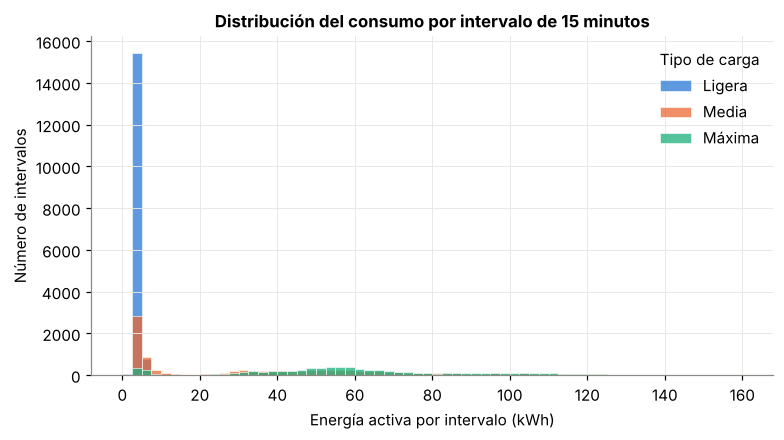

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 160, 65)
for c in ORDEN_CARGA:
    ax.hist(df.loc[df["tipo_carga"] == c, "energia_kwh"], bins=bins, color=COLOR_CARGA[c],
            alpha=0.75, label=ETQ_CARGA[c], edgecolor="white", linewidth=0.5)
ax.set(title="Distribución del consumo por intervalo de 15 minutos",
       xlabel="Energía activa por intervalo (kWh)", ylabel="Número de intervalos")
ax.legend(title="Tipo de carga", frameon=False)
guardar(fig, "fig01_distribucion_consumo")
plt.show()

**Interpretación:**
- La distribución es **bimodal**: hay un gran pico cerca de 3–5 kWh (planta en reposo o con carga base) y otro grupo amplio entre 30 y 150 kWh (producción).
- La carga ligera se concentra en el primer pico. Las cargas media y máxima se **superponen** en el rango de producción, así que la energía por sí sola no basta para distinguirlas.
- También hay intervalos de carga "máxima" con muy poco consumo. Esto sugiere que la etiqueta `Load_Type` responde en parte a **franjas horarias predefinidas** y no solo a la potencia medida (lo verificamos en las Figuras 7 y 8).

### Figura 2. Perfil horario promedio: días laborables vs fin de semana
**Para qué:** identificar en qué horas se concentra la producción. Agrupamos por hora y tipo de día, y calculamos la demanda media (kW).

hora          0     1     2     3     4     5     6     7      8      9      10     11    12     13     14     15     16     17     18     19     20    21    22    23
fin_semana                                                                                                                                                            
0           31.7  20.7  17.7  17.3  17.0  17.2  17.3  21.5  248.1  281.6  270.3  273.9  32.1  250.7  271.2  267.8  271.5  198.3  193.2  203.6  178.9  49.7  39.2  37.5
1           30.2  21.4  17.6  17.7  17.7  16.2  16.2  15.5   94.4  104.8  106.6   96.9  19.3   95.0  105.8  106.4   87.5   27.6   24.9   24.0   23.1  20.7  19.1  17.8


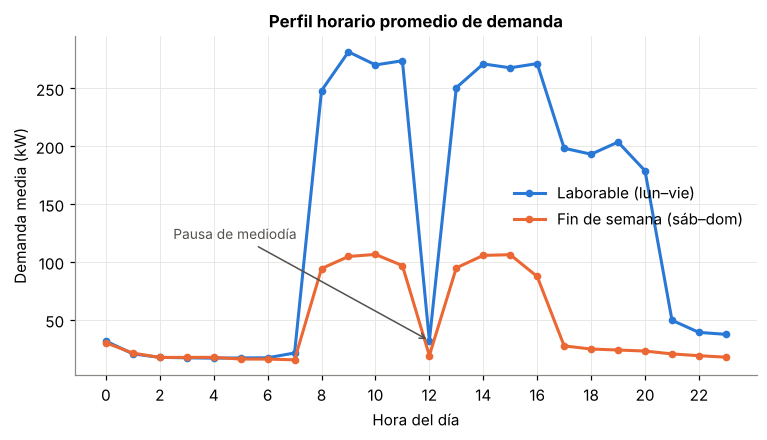

In [6]:
perfil = df.groupby(["fin_semana", "hora"])["demanda_kw"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(perfil.index, perfil[0], color=AZUL, lw=2, marker="o", ms=4, label="Laborable (lun–vie)")
ax.plot(perfil.index, perfil[1], color=NARANJA, lw=2, marker="o", ms=4, label="Fin de semana (sáb–dom)")
ax.set(title="Perfil horario promedio de demanda", xlabel="Hora del día", ylabel="Demanda media (kW)", xticks=range(0, 24, 2))
ax.annotate("Pausa de mediodía", xy=(12, perfil.loc[12, 0]), xytext=(2.5, 120),
            arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e", fontsize=9)
ax.legend(frameon=False)
guardar(fig, "fig02_perfil_horario")
plt.show()
print(perfil.round(1).T.to_string())

**Interpretación:**
- En días laborables la demanda sube a partir de las **8–9 h**, se mantiene alta hasta las **20–21 h** y cae en la noche: es un patrón de **dos turnos diurnos**.
- Hay una **caída marcada a las 12 h**, consistente con una **pausa de almuerzo** que detiene parte de los equipos. Al reanudar se produce un nuevo arranque, lo que puede generar picos de demanda.
- En fin de semana la demanda es mucho menor, aunque no nula: hay producción parcial algunos sábados.
- Entre las 0 y las 7 h la demanda es baja y casi constante: es la **carga base** de la planta.

### Figura 3. Mapa de calor: demanda media por hora y día de la semana
**Para qué:** combinar las dos dimensiones de calendario en una sola imagen. Usamos una escala de **un solo color** (claro = poco, oscuro = mucho), adecuada para magnitudes.

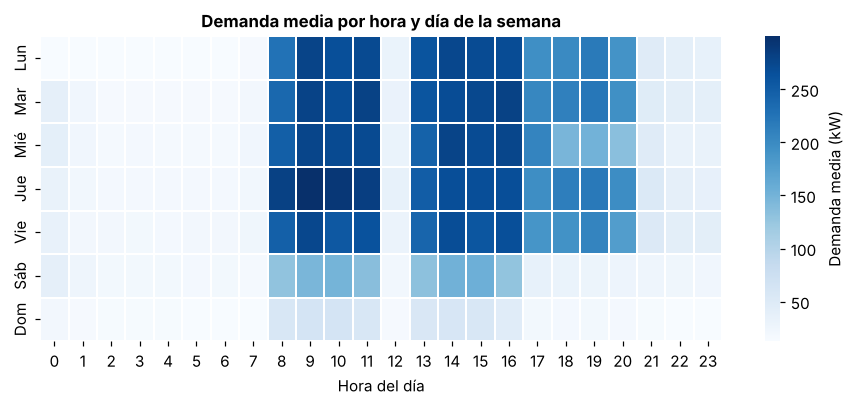

In [7]:
mapa = df.pivot_table(index="dia_num", columns="hora", values="demanda_kw", aggfunc="mean")
mapa.index = DIAS_ES
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(mapa, cmap="Blues", ax=ax, cbar_kws={"label": "Demanda media (kW)"}, linewidths=0.3, linecolor="white")
ax.set(title="Demanda media por hora y día de la semana", xlabel="Hora del día", ylabel="")
ax.grid(False)
guardar(fig, "fig03_mapa_calor_hora_dia")
plt.show()

**Interpretación:**
- De lunes a viernes el patrón es **muy regular**: la operación sigue un horario estable. Esto favorece la planificación de la demanda.
- El **sábado** tiene actividad reducida y el **domingo** es prácticamente un día sin producción.
- Las franjas oscuras (9–11 h y 13–20 h entre semana) son las de **mayor demanda**: ahí se debería concentrar la gestión de picos.

### Figura 4. Energía diaria a lo largo del año
**Para qué:** ver tendencias, estacionalidad y días atípicos. Graficamos la energía de cada día y una **media móvil de 7 días** (`.rolling(7).mean()`), que suaviza la variación entre días laborables y fines de semana para mostrar la tendencia.

Energía mensual (MWh):
mes
1     126.2
2      91.5
3      80.2
4      78.8
5      79.1
6      65.4
7      81.7
8      68.6
9      57.9
10     84.7
11     86.2
12     59.4
Mes máximo/mínimo: 2.18 veces


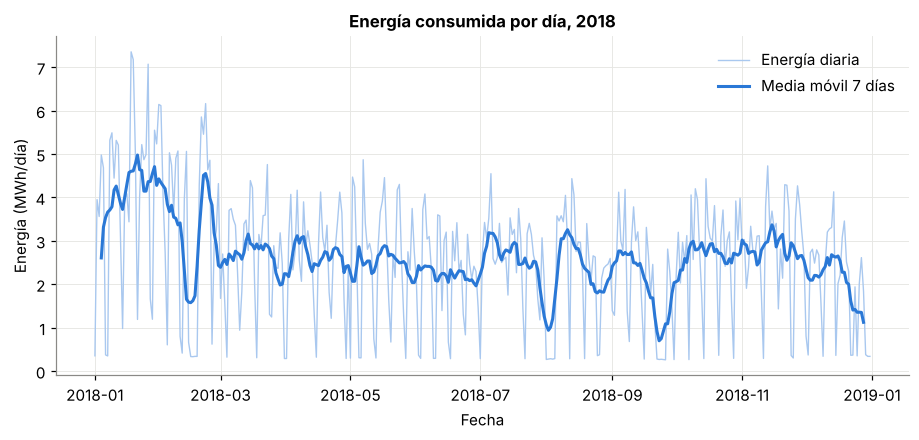

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(diaria["fecha"], diaria["energia_kwh"] / 1000, color="#a9c8ef", lw=0.9, label="Energía diaria")
ax.plot(diaria["fecha"], diaria["energia_kwh"].rolling(7, center=True).mean() / 1000, color=AZUL, lw=2, label="Media móvil 7 días")
ax.set(title="Energía consumida por día, 2018", xlabel="Fecha", ylabel="Energía (MWh/día)")
ax.legend(frameon=False)
guardar(fig, "fig04_energia_diaria")
plt.show()
mensual = df.groupby("mes")["energia_kwh"].sum() / 1000
print("Energía mensual (MWh):"); print(mensual.round(1).to_string())
print(f"Mes máximo/mínimo: {mensual.max()/mensual.min():.2f} veces")

**Interpretación:**
- **Enero** es el mes de mayor consumo (~126 MWh) y **septiembre** el de menor (~58 MWh): una diferencia de **2,2 veces**. Durante enero se observan días con consumos muy superiores al resto del año, lo que sugiere operación extendida (más horas o turnos nocturnos).
- Hay caídas abruptas a casi cero en días puntuales entre semana (por ejemplo, a mediados de febrero, que coincide con el feriado del Año Nuevo Lunar coreano): son **paradas de planta**.
- Estos cambios indican que existen **distintos tipos de día operativo**, lo que justifica aplicar clustering sobre los perfiles diarios (Fase 4).

### Figura 5. Matriz de correlación
**Concepto:** el coeficiente de correlación de Pearson ($r$) mide la relación **lineal** entre dos variables. Va de −1 (relación inversa perfecta) a +1 (relación directa perfecta); 0 indica ausencia de relación lineal. Usamos una escala de **dos colores con centro neutro** porque la correlación tiene signo.

**Recordatorio:** correlación **no implica causalidad**.

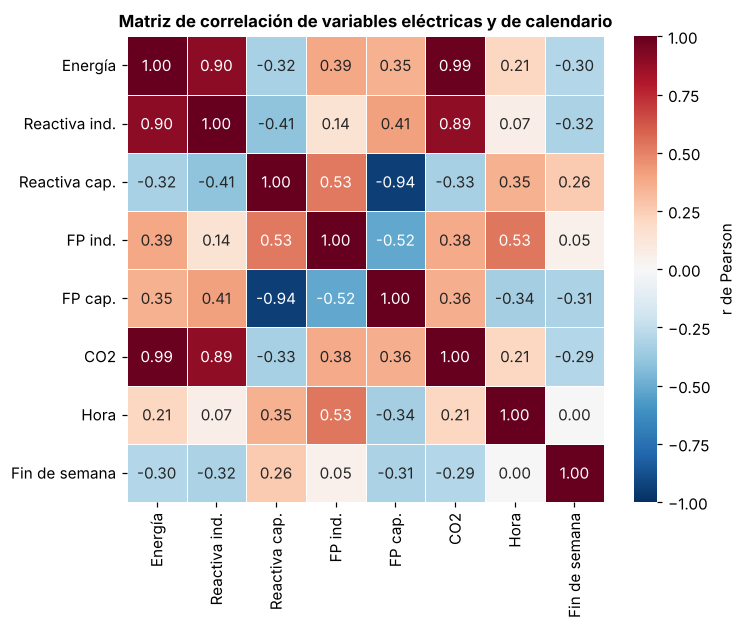

In [9]:
vars_corr = ["energia_kwh", "reactiva_ind_kvarh", "reactiva_cap_kvarh", "fp_ind_pct", "fp_cap_pct", "co2_t", "hora", "fin_semana"]
etiquetas = ["Energía", "Reactiva ind.", "Reactiva cap.", "FP ind.", "FP cap.", "CO2", "Hora", "Fin de semana"]
corr = df[vars_corr].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            xticklabels=etiquetas, yticklabels=etiquetas, cbar_kws={"label": "r de Pearson"}, linewidths=0.4, linecolor="white")
ax.set_title("Matriz de correlación de variables eléctricas y de calendario")
ax.grid(False)
guardar(fig, "fig05_correlacion")
plt.show()

**Interpretación:**
- **Energía y CO₂: r = 0,99.** Confirma lo visto en el ETL: el CO₂ es una transformación del consumo. Por eso se excluye de los modelos.
- **Energía y reactiva inductiva: r = 0,90.** Al aumentar la producción entran en operación motores y hornos, que consumen energía reactiva inductiva.
- **Reactiva capacitiva y FP capacitivo: r = −0,94.** Es una relación matemática: más reactiva capacitiva implica un FP capacitivo menor.
- **Fin de semana** se relaciona negativamente con la energía (r ≈ −0,2): confirma la menor actividad.
- Como varias variables están muy correlacionadas, hay **información redundante**. Esto justifica técnicas de reducción de dimensionalidad (PCA y LDA).

### Figura 6. Calidad de la energía: porcentaje de tiempo con FP < 90 % por hora
**Para qué:** identificar **cuándo** se produce el bajo factor de potencia, para saber dónde actuar.

Reactiva excedente (base 15 min) por tipo de carga, % del total:
tipo_carga
Light_Load      69.3
Medium_Load     10.9
Maximum_Load    19.8


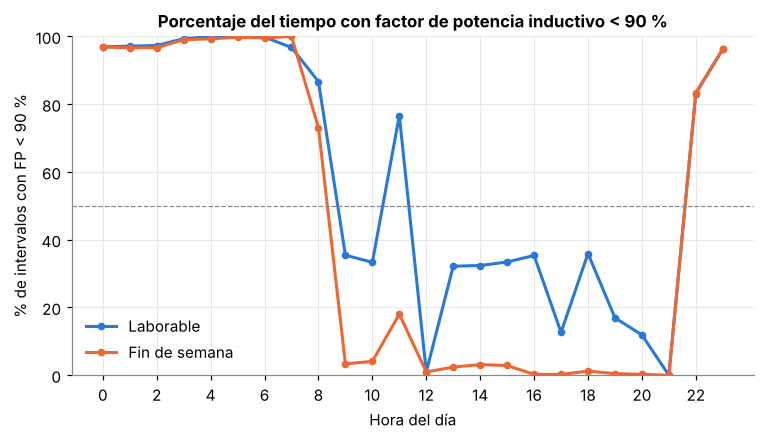

In [10]:
fp_hora = df.groupby(["hora", "fin_semana"])["fp_bajo"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fp_hora.index, fp_hora[0], color=AZUL, lw=2, marker="o", ms=4, label="Laborable")
ax.plot(fp_hora.index, fp_hora[1], color=NARANJA, lw=2, marker="o", ms=4, label="Fin de semana")
ax.axhline(50, color="#8a8986", lw=0.8, ls="--")
ax.set(title="Porcentaje del tiempo con factor de potencia inductivo < 90 %", xlabel="Hora del día",
       ylabel="% de intervalos con FP < 90 %", xticks=range(0, 24, 2), ylim=(0, 100))
ax.legend(frameon=False)
guardar(fig, "fig06_fp_bajo_por_hora")
plt.show()
exceso_tipo = df.groupby("tipo_carga", observed=True)["exceso_reactiva_kvarh"].sum()
print("Reactiva excedente (base 15 min) por tipo de carga, % del total:")
print((exceso_tipo / exceso_tipo.sum() * 100).round(1).to_string())

**Interpretación:**
- En la **noche y la madrugada (23–7 h)** el FP es inferior a 90 % entre el **96 % y el 100 % del tiempo** (a las 22 h, el 83 %), tanto en días laborables como en fines de semana. Cuando la planta está en reposo, los equipos que siguen energizados (transformadores, motores en vacío) consumen proporcionalmente mucha energía reactiva.
- En horas de producción de días laborables el problema baja a ~30–35 % del tiempo, con un repunte a las **11 h (77 %)**, justo antes de la pausa de mediodía. En los fines de semana, durante el día, el FP es casi siempre adecuado.
- El **69 %** de la reactiva excedente del año ocurre en periodos de carga ligera.
- **Implicación de gestión:** una compensación de reactiva **fija** no sirve, porque la necesidad cambia según la hora. Se requiere un **banco de condensadores automático (escalonado)** que ajuste la compensación a la carga. Lo desarrollamos en el plan de acción.

### Figura 7. Energía por tipo de carga
**Para qué:** verificar si la etiqueta `tipo_carga` corresponde realmente a niveles de consumo distintos. Un **diagrama de caja (boxplot)** muestra la mediana (línea central), el 50 % central de los datos (caja) y la dispersión (bigotes).

Media: 40.4 % de sus intervalos tienen menos de 10 kWh (nivel de carga base)
Máxima: 8.9 % de sus intervalos tienen menos de 10 kWh (nivel de carga base)

Tipo de carga por hora (% de intervalos):
hora             0      1      2      3      4      5      6      7      8     9     10    11    12    13    14    15    16    17    18    19    20    21    22     23
tipo_carga                                                                                                                                                            
Light_Load    100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  17.0  100.0
Medium_Load     0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0  83.0   0.0   0.0  83.0  26.0  26.0  26.0  26.0  57.0  57.0  57.0  83.0  83.0  57.0    0.0
Maximum_Load    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0   0.0  83.0  83.0   0.0  57.0  57.0  57.0  57.0  26.0  26.0

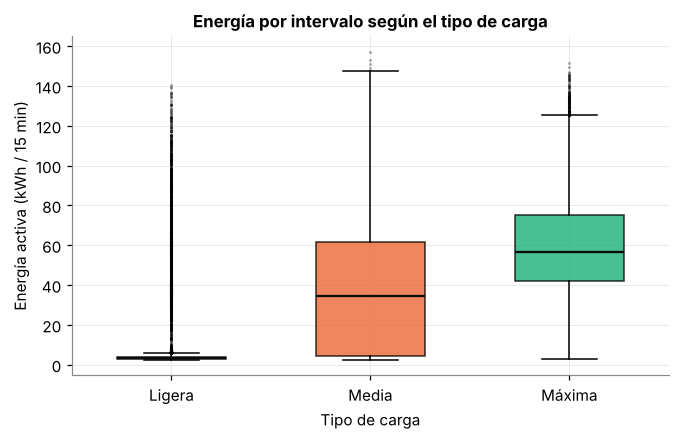

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
datos = [df.loc[df["tipo_carga"] == c, "energia_kwh"] for c in ORDEN_CARGA]
bp = ax.boxplot(datos, patch_artist=True, widths=0.55, flierprops=dict(marker=".", markersize=2, alpha=0.3),
                medianprops=dict(color="#0b0b0b", lw=1.5))
for patch, c in zip(bp["boxes"], ORDEN_CARGA):
    patch.set_facecolor(COLOR_CARGA[c]); patch.set_alpha(0.8)
ax.set_xticks([1, 2, 3], [ETQ_CARGA[c] for c in ORDEN_CARGA])
ax.set(title="Energía por intervalo según el tipo de carga", xlabel="Tipo de carga", ylabel="Energía activa (kWh / 15 min)")
guardar(fig, "fig07_boxplot_tipo_carga")
plt.show()
for c in ["Medium_Load", "Maximum_Load"]:
    p = (df.loc[df["tipo_carga"] == c, "energia_kwh"] < 10).mean() * 100
    print(f"{ETQ_CARGA[c]}: {p:.1f} % de sus intervalos tienen menos de 10 kWh (nivel de carga base)")
print("\nTipo de carga por hora (% de intervalos):")
print((pd.crosstab(df["hora"], df["tipo_carga"], normalize="index") * 100).round(0).T.to_string())

**Interpretación:**
- Las medianas crecen de ligera a máxima, como era de esperar. Pero las cajas de **media y máxima se superponen bastante**, y el **40 %** de los intervalos de carga "media" tiene consumos de **carga base** (< 10 kWh).
- Entre las 0 y las 8 h y a las 23 h **todos** los intervalos son "ligeros", y los porcentajes por hora se repiten de forma exacta (17 %, 26 %, 57 %, 83 %). Esto sugiere que `tipo_carga` **no es una medición**, sino un **horario predefinido**. Lo verificamos a continuación.

### Figura 8. ¿Es `tipo_carga` un horario fijo? Verificación
**Prueba:** si `tipo_carga` fuera un horario, al conocer el **mes**, la **hora** y si el día es "todo ligero" (la mayoría de domingos y los feriados), la etiqueta debería quedar determinada sin excepciones. Medimos la **pureza**: para cada combinación (mes, hora), qué proporción de intervalos tiene la etiqueta más frecuente. Una pureza de 100 % significa que la etiqueta es una regla fija.

Días con todos sus intervalos en carga ligera: 62 | de ellos domingos: 35
Pureza de la etiqueta por (mes, hora) en los demás días: media 100.00%, mínima 100.00%


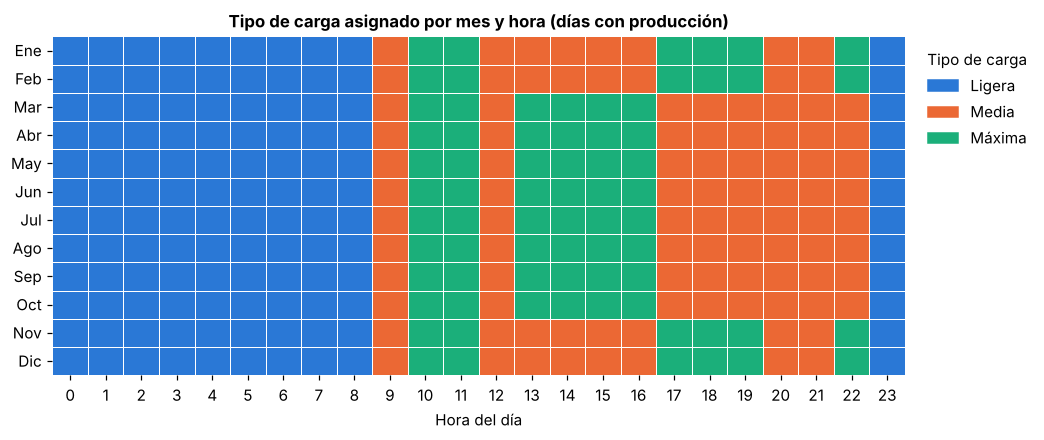

In [12]:
dia_todo_ligero = df.groupby("fecha")["tipo_carga"].transform(lambda s: (s == "Light_Load").all())
print("Días con todos sus intervalos en carga ligera:", df.loc[dia_todo_ligero, "fecha"].nunique(),
      "| de ellos domingos:", df.loc[dia_todo_ligero & (df["dia_num"] == 6), "fecha"].nunique())
resto = df[~dia_todo_ligero]
pureza = resto.groupby(["mes", "hora"])["tipo_carga"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"Pureza de la etiqueta por (mes, hora) en los demás días: media {pureza.mean():.2%}, mínima {pureza.min():.2%}")

codigo_num = resto["tipo_carga"].cat.codes          # 0 = ligera, 1 = media, 2 = máxima
mapa_cod = codigo_num.groupby([resto["mes"], resto["hora"]]).agg(lambda s: s.mode()[0]).unstack()
mapa_cod.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(mapa_cod, cmap=ListedColormap([COLOR_CARGA[c] for c in ORDEN_CARGA]), cbar=False, ax=ax, linewidths=0.4, linecolor="white")
ax.set(title="Tipo de carga asignado por mes y hora (días con producción)", xlabel="Hora del día", ylabel="")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLOR_CARGA[c], label=ETQ_CARGA[c]) for c in ORDEN_CARGA], title="Tipo de carga",
          bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.grid(False)
guardar(fig, "fig08_horario_tipo_carga")
plt.show()

**Interpretación (hallazgo clave):**
- La pureza es del **100 %**: `tipo_carga` es una **regla fija de calendario**, no una medición. Hay dos patrones de temporada: **noviembre a febrero**, con carga máxima a las 10–12 h, 17–20 h y 22 h, y **marzo a octubre**, con carga máxima a las 10–12 h y 13–17 h. Además, 62 días del año (35 domingos y el resto feriados o sábados) se etiquetan como "ligeros" durante todo el día.
- Esta estructura coincide con la de una **tarifa eléctrica por franjas horarias** (*time-of-use*): periodos de punta, intermedios y valle que cambian según la temporada. La fuente no lo documenta explícitamente, así que lo presentamos como **interpretación**, no como un hecho confirmado.
- **Consecuencia metodológica:** si usáramos `tipo_carga` como variable objetivo con la hora y el mes como entradas, el modelo solo "redescubriría" el horario. Sería una clasificación trivial, con **fuga de información**. Por eso, en la Fase 4 definimos un **problema de clasificación con valor operativo real** (H2), y usamos `tipo_carga` como lo que es: el **periodo tarifario**, conocido de antemano.
- **Implicación de gestión:** el **44,9 %** de la energía se consume en periodos de carga **máxima** (punta), que en las tarifas por franjas suelen ser los más costosos.

## 5. Insights accionables y hipótesis para la Fase 4
**Insights accionables del EDA:**
1. **Bajo factor de potencia sistemático** (FP < 90 % durante el ~55 % del tiempo), concentrado en horas de baja carga → compensación de reactiva automática.
2. **Carga base elevada** (~20 kW permanentes en la noche y los domingos) → auditar consumos en vacío.
3. **Factor de carga muy bajo** (0,17) con picos al reanudar turnos y después de la pausa de mediodía → escalonar arranques.
4. **Variación fuerte entre meses y tipos de día** → planificar la energía según el tipo de jornada.

**Hipótesis analíticas (se responden en la Fase 4):**

| # | Hipótesis | Técnica |
|---|---|---|
| H1 | Los 365 días se agrupan en un número reducido de **tipos de jornada operativa** con perfiles horarios distintos (p. ej., producción normal, extendida y sin producción). | Clustering |
| H2 | Es posible **anticipar con una hora de antelación** la severidad del exceso de energía reactiva (sin exceso / moderado / alto), usando solo información disponible antes de esa hora, con un desempeño claramente superior a una línea base ingenua. | Clasificación |
| H3 | La mayor parte de la variabilidad de los perfiles diarios (≥ 80 %) se explica con pocas componentes, interpretables como "nivel de actividad diurna" y "operación nocturna". | PCA |
| H4 | Una proyección discriminante lineal (LDA) a 2 ejes separa los niveles de severidad y conserva (o mejora) el desempeño de los clasificadores. | LDA |

La H2 está directamente conectada con el hallazgo más costoso del EDA (más de la mitad de las horas con reactiva > 50 % de la activa): una alerta anticipada permitiría ajustar la compensación **antes** de incurrir en el exceso.

In [13]:
hip = pd.DataFrame({
    "hipotesis": ["H1", "H2", "H3", "H4"],
    "enunciado": ["Los días se agrupan en pocos tipos de jornada con perfiles distintos",
                  "La severidad del exceso de reactiva de la próxima hora es predecible mejor que una línea base",
                  "≥80 % de la varianza de los perfiles diarios en pocas componentes",
                  "LDA a 2 ejes separa la severidad y conserva o mejora el desempeño"],
    "tecnica": ["Clustering", "Clasificación", "PCA", "LDA"]})
hip.to_csv(RUTA_TABLAS / "hipotesis.csv", index=False)
hip

,hipotesis,enunciado,tecnica
0,H1,Los días se agrupan en pocos tipos de jornada con perfiles distintos,Clustering
1,H2,La severidad del exceso de reactiva de la próxima hora es predecible mejor que una línea base,Clasificación
2,H3,≥80 % de la varianza de los perfiles diarios en pocas componentes,PCA
3,H4,LDA a 2 ejes separa la severidad y conserva o mejora el desempeño,LDA
